In [80]:
import numpy as np
import pandas as pd
import itertools
from datetime import datetime as dt
import lightgbm as lgb

from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import warnings
warnings.simplefilter("ignore")

### Load DATA

In [3]:
df = pd.read_csv('../datasets/taxi_pickups_area.csv')
df.head()

,Trip Start Timestamp,Pickup Community Area_0,Pickup Community Area_1,Pickup Community Area_2,Pickup Community Area_3,Pickup Community Area_4,Pickup Community Area_5,Pickup Community Area_6,Pickup Community Area_7,Pickup Community Area_8,...,Pickup Community Area_68,Pickup Community Area_69,Pickup Community Area_70,Pickup Community Area_71,Pickup Community Area_72,Pickup Community Area_73,Pickup Community Area_74,Pickup Community Area_75,Pickup Community Area_76,Pickup Community Area_77
0,2019-04-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,2019-04-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
2,2019-04-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
3,2019-04-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,2019-04-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
df.describe()

,Pickup Community Area_0,Pickup Community Area_1,Pickup Community Area_2,Pickup Community Area_3,Pickup Community Area_4,Pickup Community Area_5,Pickup Community Area_6,Pickup Community Area_7,Pickup Community Area_8,Pickup Community Area_9,...,Pickup Community Area_68,Pickup Community Area_69,Pickup Community Area_70,Pickup Community Area_71,Pickup Community Area_72,Pickup Community Area_73,Pickup Community Area_74,Pickup Community Area_75,Pickup Community Area_76,Pickup Community Area_77
count,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,...,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000
mean,15.748140,1.090650,1.083457,2.617188,0.858631,0.559524,9.733507,5.498264,83.933160,0.015501,...,0.075521,0.114955,0.063988,0.116567,0.024802,0.097594,0.010789,0.064484,30.329117,2.078249
std,21.585934,1.532432,1.492585,2.876240,1.210400,0.885860,11.543953,5.521181,80.356011,0.127494,...,0.296117,0.363339,0.275725,0.387455,0.174329,0.347952,0.103313,0.272441,33.768111,2.343545
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,19.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.000000
50%,6.000000,1.000000,1.000000,2.000000,0.000000,0.000000,6.000000,4.000000,45.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,1.000000
75%,24.000000,2.000000,2.000000,4.000000,1.000000,1.000000,13.000000,9.000000,138.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,49.000000,3.000000
max,99.000000,22.000000,12.000000,19.000000,8.000000,7.000000,99.000000,30.000000,384.000000,2.000000,...,4.000000,3.000000,3.000000,5.000000,4.000000,4.000000,1.000000,3.000000,169.000000,14.000000


In [5]:
df.index = df['Trip Start Timestamp']
df = df.drop('Trip Start Timestamp', axis=1)
df

,Pickup Community Area_0,Pickup Community Area_1,Pickup Community Area_2,Pickup Community Area_3,Pickup Community Area_4,Pickup Community Area_5,Pickup Community Area_6,Pickup Community Area_7,Pickup Community Area_8,Pickup Community Area_9,...,Pickup Community Area_68,Pickup Community Area_69,Pickup Community Area_70,Pickup Community Area_71,Pickup Community Area_72,Pickup Community Area_73,Pickup Community Area_74,Pickup Community Area_75,Pickup Community Area_76,Pickup Community Area_77
Trip Start Timestamp,,,,,,,,,,,,,,,,,,,,,
2019-04-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2019-04-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
2019-04-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
2019-04-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2019-04-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-06-23 22:45:00,4.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,0.0
2019-06-23 23:00:00,3.0,0.0,0.0,1.0,0.0,0.0,5.0,0.0,8.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,0.0
2019-06-23 23:15:00,3.0,0.0,1.0,0.0,0.0,0.0,3.0,0.0,11.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,0.0


### EDA

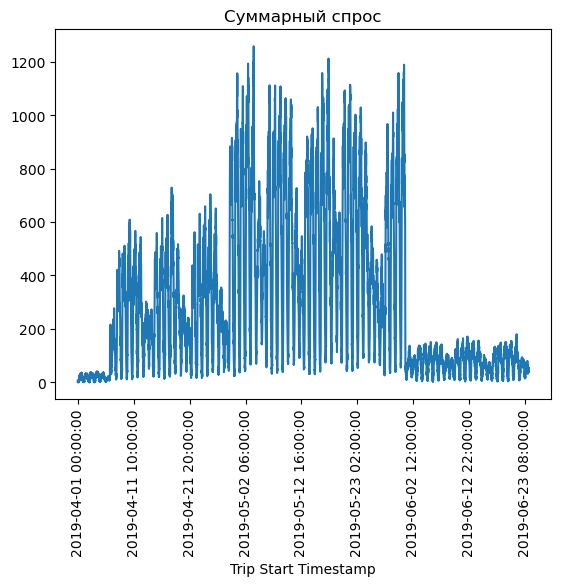

In [7]:
df.sum(axis=1).plot(rot=90, title='Суммарный спрос');

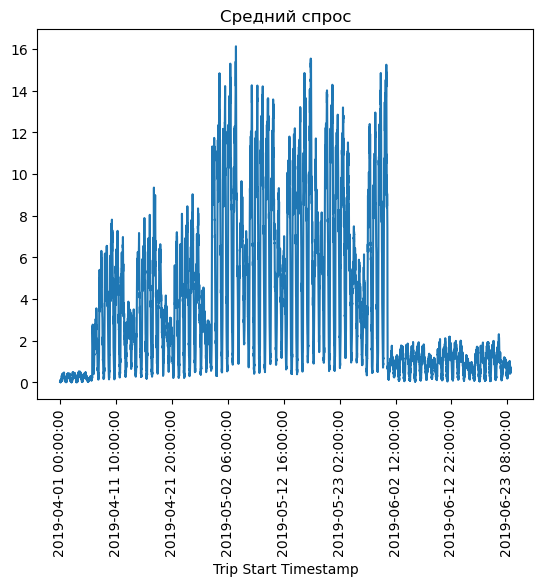

In [8]:
df.mean(axis=1).plot(rot=90, title='Средний спрос');

In [9]:
df['day'] = list(map(lambda x: pd.to_datetime(x).day, df.index))
df['hour'] = list(map(lambda x: pd.to_datetime(x).hour, df.index))
df['week_day'] = list(map(lambda x: pd.to_datetime([x]).weekday[0], df.index))
df['month'] = list(map(lambda x: pd.to_datetime(x).month, df.index))

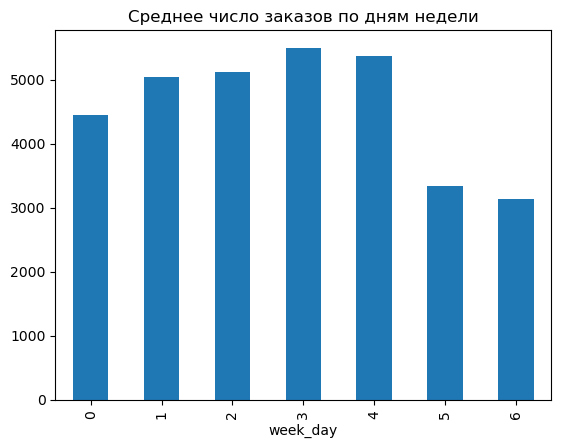

In [10]:
df.groupby('week_day').sum().mean(axis=1).plot(kind="bar", title='Среднее число заказов по дням недели');

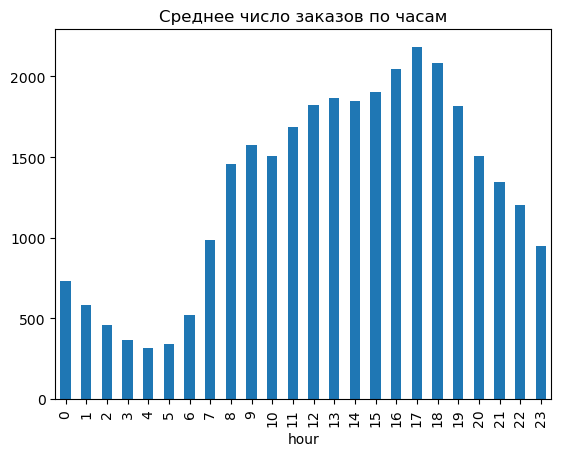

In [11]:
df.groupby('hour').sum().mean(axis=1).plot(kind="bar", title='Среднее число заказов по часам');

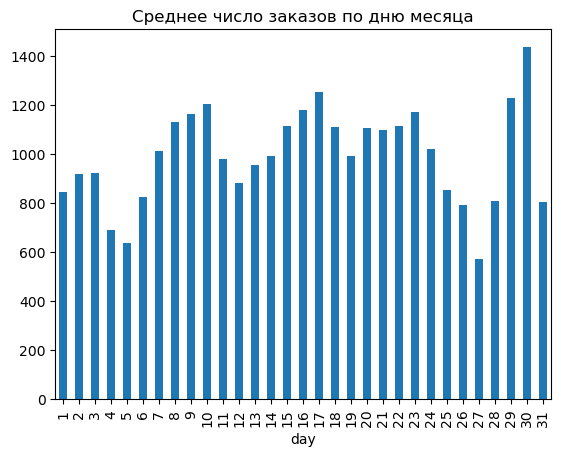

In [12]:
df.groupby('day').sum().mean(axis=1).plot(kind="bar", title='Среднее число заказов по дню месяца');

### Train test split

In [14]:
h = 24 * 4 * 7 # 24 часа, 4 точки в часе(по 15 минут), 7 дней

val_df = df.iloc[-h:]
train_df = df.iloc[:-h]

print("val период:", val_df.index.min(), "-", val_df.index.max())
print("train период:", train_df.index.min(), "-", train_df.index.max())

val период: 2019-06-17 00:00:00 - 2019-06-23 23:45:00
train период: 2019-04-01 00:00:00 - 2019-06-16 23:45:00


### Сводная таблица результатов

In [16]:
result = pd.DataFrame(columns=['Метод', 'МАЕ'])
result

,Метод,МАЕ


## 1. Наивное среднее

In [18]:
# Общее среднее
mean_all = train_df.iloc[:,:-4].mean().mean()
predicts = np.tile([mean_all] * train_df.iloc[:,:-4].shape[1], (h, 1))
mae = mean_absolute_error(predicts, val_df.iloc[:,:-4])

result.loc[len(result)] = {'Метод': 'MAE по общему среднему', 'МАЕ': round(mae, 5)}
print(f'MAE по зонам: {mae}')

MAE по зонам: 4.167760228918786


In [19]:
# Среднее по зонам
area_means = train_df.describe().loc['mean'][:-4]
predicts = np.tile(area_means, (h, 1))
mae = mean_absolute_error(predicts, val_df.iloc[:,:-4])

result.loc[len(result)] = {'Метод': 'MAE по среднему по зонам', 'МАЕ': round(mae, 5)}
print(f'MAE по зонам: {mae}')

MAE по зонам: 3.103475951132188


In [20]:
# Берем медиану а не среднее по зонам
area_medians = train_df.describe().loc['50%'][:-4]
predicts = np.tile(area_medians, (h, 1))
mae = mean_absolute_error(predicts, val_df.iloc[:,:-4])

result.loc[len(result)] = {'Метод': 'MAE по медиане по зонам', 'МАЕ': round(mae, 5)}
print(f'MAE по зонам относительно медианы: {mae}')

MAE по зонам относительно медианы: 1.331425518925519


In [21]:
# Берем посление 2 недели из train
area_means = train_df.iloc[-h * 2:].describe().loc['mean'][:-4]
predicts = np.tile(area_means, (h, 1))
mae = mean_absolute_error(predicts, val_df.iloc[:,:-4])

result.loc[len(result)] = {'Метод': 'MAE по среднему по зонам за последние 2 недели', 'МАЕ': round(mae, 5)}
print(f'MAE по зонам: {mae}')

area_medians = train_df.iloc[-h * 2:].describe().loc['50%'][:-4]
predicts = np.tile(area_medians, (h, 1))
mae = mean_absolute_error(predicts, val_df.iloc[:,:-4])

result.loc[len(result)] = {'Метод': 'MAE по медиане по зонам за последние 2 недели', 'МАЕ': round(mae, 5)}
print(f'MAE по зонам относительно медианы: {mae}')

MAE по зонам: 0.6492433812467283
MAE по зонам относительно медианы: 0.6022588522588521


In [22]:
result

,Метод,МАЕ
0,MAE по общему среднему,4.16776
1,MAE по среднему по зонам,3.10348
2,MAE по медиане по зонам,1.33143
3,MAE по среднему по зонам за последние 2 недели,0.64924
4,MAE по медиане по зонам за последние 2 недели,0.60226


## 2. Скользящее среднее

In [24]:
windows = [96, 288, 96*7, 96*14, 96*21, 96*28]  # 1д, 3д, 1нед, 2нед, 3нед, 4нед

In [25]:
best_w = 0
best_mae = 100
for w in windows:
    predicts = []
    arr = train_df.iloc[-w:, :-4].to_numpy()
    for i in range(h):
        preds = arr.mean(axis=0)
        predicts.append(preds)
        arr[:-1] = arr[1:]
        arr[-1] = preds
    mae = mean_absolute_error(predicts, val_df.iloc[:,:-4])
    print(f'Окно: {w}, mae = {mae}')
    if mae < best_mae:
        best_mae = mae
        best_w = w

print(f'Лучшее окно: {best_w}, лучшее MAE = {best_mae}')
interval = best_w / 96
result.loc[len(result)] = {'Метод': f'Скользящее окно по интервалу {interval} дней', 'МАЕ': round(best_mae, 5)}

Окно: 96, mae = 0.6781223651954595
Окно: 288, mae = 0.6517524451890373
Окно: 672, mae = 0.6427200408284311
Окно: 1344, mae = 0.6479563527248617
Окно: 2016, mae = 0.9824418948471706
Окно: 2688, mae = 1.92191514652136
Лучшее окно: 672, лучшее MAE = 0.6427200408284311


In [26]:
result

,Метод,МАЕ
0,MAE по общему среднему,4.16776
1,MAE по среднему по зонам,3.10348
2,MAE по медиане по зонам,1.33143
3,MAE по среднему по зонам за последние 2 недели,0.64924
4,MAE по медиане по зонам за последние 2 недели,0.60226
5,Скользящее окно по интервалу 7.0 дней,0.64272


## 3. Экспоненциальное сглаживание

#### Методы экспоненциального сглаживания (Exponential Smoothing)

#### 1. Простое экспоненциальное сглаживание (SES — Simple Exponential Smoothing)

**Назначение:** прогнозирование временных рядов без выраженного тренда и сезонности. Подходит как быстрый бенчмарк и для сглаживания шума.

**Суть:** прогноз на следующий шаг равен последнему сглаженному значению. Веса прошлых наблюдений убывают экспоненциально — свежие данные влияют сильнее.

**Формулы:**
$$
S_t = \alpha y_t + (1 - \alpha) S_{t-1}
$$
$$
\hat{y}_{t+1} = S_t
$$

**Параметры:**
- `smoothing_level` ($\alpha$) ∈ (0, 1) — коэффициент сглаживания. Чем ближе к 1, тем сильнее модель реагирует на последние наблюдения.

**Характер прогноза:** горизонтальный (на все шаги вперёд — одно и то же значение).

**Когда применять в пайплайне:**
- как baseline для сравнения с ML‑моделями;
- для рядов с высокой волатильностью, где нужно «снять» шум;
- на коротких окнах, где не хватает данных для тренда/сезонности.

#### 2. Метод Холта (Holt — Double Exponential Smoothing)

**Назначение:** прогнозирование временных рядов с трендом, но без выраженной сезонности (либо когда сезонность не моделируется явно).

**Суть подхода:** метод разделяет динамику ряда на две компоненты — уровень и тренд. Уровень отражает текущее значение ряда с учётом сглаживания, а тренд — скорость изменения этого уровня. Прогноз строится путём экстраполяции текущего уровня с учётом накопленного тренда.

**Формулы:**
- Уровень: $L_t = \alpha y_t + (1 - \alpha)(L_{t-1} + T_{t-1})$
- Тренд: $T_t = \beta (L_t - L_{t-1}) + (1 - \beta) T_{t-1}$
- Прогноз на $h$ шагов вперёд: $\hat{y}_{t+h} = L_t + h T_t$

**Ключевые параметры:**
- $\alpha$ (`smoothing_level`) — коэффициент сглаживания уровня (влияние текущего наблюдения).
- $\beta$ (`smoothing_trend`) — коэффициент сглаживания тренда (стабильность оценки скорости роста/падения).

**Характер прогноза:** линейный — прямая с постоянным наклоном (тренд не меняется в пределах горизонта прогноза).

**Когда особенно полезен в DS‑пайплайне:**
- При наличии устойчивого тренда без сильной сезонной компоненты.
- Как интерпретируемая альтернатива ML‑моделям: параметры $\alpha$, $\beta$ легко трактуются.
- В ансамблях — как стабильный компонент для компенсации «перегибов» более сложных моделей.
- На коротких окнах, где не хватает данных для надёжной оценки сезонности.

#### 3. Метод Хольта‑Уинтерса (Holt‑Winters — Triple Exponential Smoothing)

**Назначение:** прогнозирование временных рядов, в которых одновременно присутствуют тренд и сезонность. Это наиболее полный вариант экспоненциального сглаживания: модель явно выделяет три компоненты — уровень, тренд и сезонный эффект.

**Суть подхода:**  
Ряд декомпозируется на три составляющие, каждая из которых сглаживается своим коэффициентом. Прогноз формируется как комбинация этих компонент с учётом горизонта прогноза и текущего положения в сезонном цикле. Такой подход особенно полезен, когда сезонный профиль стабилен и повторяется из цикла в цикл.

---

#### Формулы (аддитивная версия)

- **Уровень:** $L_t = \alpha (y_t - S_{t-m}) + (1 - \alpha)(L_{t-1} + T_{t-1})$
- **Тренд:** $T_t = \beta (L_t - L_{t-1}) + (1 - \beta) T_{t-1}$
- **Сезонность:** $S_t = \gamma (y_t - L_t) + (1 - \gamma) S_{t-m}$
- **Прогноз на $h$ шагов вперёд:** $\hat{y}_{t+h} = L_t + h T_t + S_{t+h-m(k)}$,  
  где $m$ — длина сезона, $k$ — номер цикла, а $S_{t+h-m(k)}$ выбирает нужный сезонный коэффициент из прошлого.

> Для мультипликативной сезонности формулы модифицируются так, чтобы сезонный эффект умножался, а не прибавлялся. В `statsmodels` это задаётся параметром `seasonal='mul'`.

---

#### Ключевые параметры

- $\alpha$ (`smoothing_level`) — отвечает за сглаживание уровня: насколько модель доверяет текущему наблюдению относительно накопленной истории.
- $\beta$ (`smoothing_trend`) — сглаживание тренда: стабильность оценки скорости роста/падения.
- $\gamma$ (`smoothing_seasonal`) — сглаживание сезонности: насколько быстро модель адаптируется к изменениям сезонного профиля.
- `seasonal_periods` — длина одного сезонного цикла в точках ряда. Например, при 15‑минутных интервалах дневная сезонность равна $24 \times 4 = 96$ точкам.

Параметры обычно подбирают оптимизацией по обучающей выборке (например, минимизацией MSE). В `statsmodels` это делает `fit(optimized=True)`.

---

#### Типы сезонности

- **Аддитивная** (`seasonal='add'`): сезонный эффект постоянен по величине независимо от уровня ряда. Подходит, если амплитуда колебаний примерно одинакова при разных уровнях ряда.
- **Мультипликативная** (`seasonal='mul'`): сезонный эффект пропорционален уровню ряда. Применяется, когда размах сезонных колебаний растёт вместе с уровнем (например, продажи растут, и сезонный всплеск тоже становится больше).

---

#### Критическое требование к данным

Для корректной инициализации сезонных компонент необходимо **минимум два полных сезонных цикла**.  
Если `seasonal_periods = 96`, то нужно не менее $2 \times 96 = 192$ наблюдений. При меньшем объёме возникает ошибка вида:
> `ValueError: Cannot compute initial seasonals using heuristic method with less than two full seasonal cycles in the data.`

Это важно учитывать при работе с окнами разной длины: на коротких окнах (например, 96 или 288 точек, если сезонность 96) метод HW либо не запустится, либо будет давать нестабильные результаты.

---

### Когда особенно полезен в DS‑пайплайне

- **Есть стабильная сезонность** (дневная, недельная и т. п.) и её профиль повторяется.
- **Горизонт прогноза пересекает разные фазы сезона** — модель учитывает, в какой части цикла находится прогноз.
- **Нужны интерпретируемые прогнозы**: параметры $\alpha$, $\beta$, $\gamma$ и компоненты (уровень, тренд, сезонность) можно использовать как признаки или для диагностики.
- **Ансамблирование**: HW даёт уникальный вклад за счёт учёта сезонности, который не воспроизводят SES и Holt.


Практические советы под пайплайн (окна разной длины, сезонность 96):

    -Короткие окна (96, 288): используйте SES и Holt. HW не стоит запускать — не хватит данных для надёжной инициализации сезонности.
    -Длинные окна (≥192): добавляйте HW с seasonal_periods=96.
    -Ансамблирование: комбинируйте прогнозы разных методов и окон, оптимизируя веса на валидационном куске — это повышает устойчивость и точность.
    -Обработка пропусков: если HW не может быть применён к какому‑то окну, используйте прогноз от Holt как fallback‑вариант.

In [32]:
def forecast_es_2d(y, window_size, h, method='ses', seasonal_periods=None):
    if y.ndim != 2:
        raise ValueError("y должен быть 2D массивом (n_timesteps, n_features)")
    n_features = y.shape[1]
    forecasts = np.empty((h, n_features), dtype=float)

    for col in range(n_features):
        series = y[-window_size:, col]
        if method == 'ses':
            model = ExponentialSmoothing(series, trend=None, seasonal=None)
        elif method == 'holt':
            model = ExponentialSmoothing(series, trend='add', seasonal=None)
        elif method == 'hw':
            if seasonal_periods is None:
                raise ValueError("Для метода 'hw' нужно указать seasonal_periods")
            min_len = 2 * seasonal_periods
            if window_size < min_len:
                forecasts[:, col] = np.nan
                continue
            model = ExponentialSmoothing(
                series,
                trend='add',
                seasonal='add',
                seasonal_periods=seasonal_periods
            )
        else:
            raise ValueError("method должен быть 'ses', 'holt' или 'hw'")

        fit = model.fit(optimized=True, use_brute=True)
        fcst = fit.forecast(h)
        forecasts[:, col] = fcst

    return forecasts

In [43]:
windows = [96, 288, 672, 1344]  # 1д, 3д, 1нед, 2нед
h = 672
y_2d = train_df.iloc[:, :-4].to_numpy()

results_w = {}

for w in windows:
    for method in ['ses', 'holt', 'hw']:
        key = (w, method)
        seasonal = 96 if method == 'hw' else None
        fcst_2d = forecast_es_2d(
            y=y_2d,
            window_size=w,
            h=h,
            method=method,
            seasonal_periods=seasonal
        )
        results_w[key] = fcst_2d

In [44]:
best_method = None
best_mae = 100

best_ses = None
best_ses_mae = 100
best_holt = None
best_holt_mae = 100
best_hw = None
best_hw_mae = 100

for k, v in results_w.items():
    v = np.nan_to_num(v, nan=0.0)
    mae = mean_absolute_error(v, val_df.iloc[:,:-4])
    print(f'{k}, mae = {mae}')
    if mae < best_mae:
        best_mae = mae
        best_method = k
    if k[1] == 'ses' and mae < best_ses_mae:
        best_ses = k[0]
        best_ses_mae = mae
    if k[1] == 'holt' and mae < best_holt_mae:
        best_holt = k[0]
        best_holt_mae = mae
    if k[1] == 'hw' and mae < best_hw_mae:
        best_hw = k[0]
        best_hw_mae = mae
        
print(f'\nЛучший метод: {best_method}, mae = {best_mae}')
print(f'\nЛучший метод ses: {best_ses}, mae = {best_ses_mae}')
print(f'Лучший метод holt: {best_holt}, mae = {best_holt_mae}')
print(f'Лучший метод hw: {best_hw}, mae = {best_hw_mae}')

(96, 'ses'), mae = 0.7556197631255542
(96, 'holt'), mae = 3.740192818096774
(96, 'hw'), mae = 0.9157890720390722
(288, 'ses'), mae = 0.7648386566710792
(288, 'holt'), mae = 1.6235670099852773
(288, 'hw'), mae = 4.002844969095307
(672, 'ses'), mae = 0.7648822543058308
(672, 'holt'), mae = 2.640962723634561
(672, 'hw'), mae = 0.7264930828025434
(1344, 'ses'), mae = 0.7672603199329924
(1344, 'holt'), mae = 1.140398445929472
(1344, 'hw'), mae = 0.689115089986669

Лучший метод: (1344, 'hw'), mae = 0.689115089986669

Лучший метод ses: 96, mae = 0.7556197631255542
Лучший метод holt: 1344, mae = 1.140398445929472
Лучший метод hw: 1344, mae = 0.689115089986669


In [45]:
interval = best_method[0] / 96
result.loc[len(result)] = {'Метод': f'Эксоненциальное сглаживание методом Holt-Winters с интервалом {interval} дней', 'МАЕ': round(best_mae, 5)}

In [46]:
result

,Метод,МАЕ
0,MAE по общему среднему,4.16776
1,MAE по среднему по зонам,3.10348
2,MAE по медиане по зонам,1.33143
3,MAE по среднему по зонам за последние 2 недели,0.64924
4,MAE по медиане по зонам за последние 2 недели,0.60226
5,Скользящее окно по интервалу 7.0 дней,0.64272
6,Эксоненциальное сглаживание методом Holt-Winte...,0.68912


## 4. SARIMA

In [48]:
def find_best_sarima(series, seasonal_periods=96, max_p=1, max_d=1, max_q=1,
                     max_P=1, max_D=0, max_Q=0):
    """
    Подбирает SARIMA(p,d,q)(P,D,Q,S) с минимальным AIC для одного ряда.
    Возвращает модель и её параметры.
    """
    # Базовая очистка
    s = series.copy().astype(float)
    if s.isna().any():
        s = s.ffill().bfill()

    p_vals = range(max_p + 1)
    d_vals = range(max_d + 1)
    q_vals = range(max_q + 1)
    P_vals = range(max_P + 1)
    D_vals = range(max_D + 1)
    Q_vals = range(max_Q + 1)
    max_params = len(p_vals) + len(d_vals) + len(q_vals) + len(P_vals) + len(D_vals) + len(Q_vals)
    #print(f'Перебор по сетку из {max_params} вариаций')

    best_aic = np.inf
    best_model = None
    best_order = None

    i = 1
    for order in itertools.product(p_vals, d_vals, q_vals):
        for seasonal_order in itertools.product(P_vals, D_vals, Q_vals):
            #print(f'Итерация номер: {i}')
            i = i + 1
            try:
                model = SARIMAX(
                    s,
                    order=order,
                    seasonal_order=seasonal_order + (seasonal_periods,),
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )
                res = model.fit(disp=False)
                if res.aic < best_aic:
                    best_aic = res.aic
                    best_model = res
                    best_order = (order, seasonal_order)
            except Exception:
                continue
    return best_model, best_order, best_aic

In [49]:
def forecast_all_columns(df, horizon=672, seasonal_periods=96):
    forecast_df = pd.DataFrame(index=pd.RangeIndex(start=0, stop=horizon))
    meta_df = []

    for col in df.columns:
        series = df[col]
        model, order, aic = find_best_sarima(series, seasonal_periods=seasonal_periods)
        if model is None:
            forecast_df[col] = np.nan
            meta_df.append({'column': col, 'best_order': None, 'aic': np.nan})
            continue

        fc = model.get_forecast(steps=horizon)
        forecast_df[col] = fc.predicted_mean.values
        meta_df.append({
            'column': col,
            'best_order': f"{order[0]}{order[1]}",
            'aic': aic
        })

    meta_df = pd.DataFrame(meta_df)
    return forecast_df, meta_df

In [50]:
horizon = 672
seasonal_periods = 96

forecasts, meta = forecast_all_columns(train_df.iloc[:, :-1 * (len(train_df.columns) - 1)], horizon=horizon, seasonal_periods=seasonal_periods)

print(meta)
print(forecasts.head())

                    column          best_order           aic
0  Pickup Community Area_0  (1, 1, 1)(1, 0, 0)  44497.751248
   Pickup Community Area_0
0                 3.008892
1                 1.382708
2                 1.746927
3                 2.120131
4                 1.933953


In [51]:
def best_sarima(series, seasonal_periods=96):
    s = series.copy().astype(float)
    if s.isna().any():
        s = s.ffill().bfill()
    model = SARIMAX(
        s,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 0, seasonal_periods),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    res = model.fit(disp=False)
    return res

def forecast_all_columns(df, horizon=672, seasonal_periods=96):
    forecast_df = pd.DataFrame(index=pd.RangeIndex(start=0, stop=horizon))
    for col in df.columns:
        series = df[col]
        model = best_sarima(series, seasonal_periods=seasonal_periods)
        if model is None:
            forecast_df[col] = np.nan
            continue
        fc = model.get_forecast(steps=horizon)
        forecast_df[col] = fc.predicted_mean.values
    return forecast_df

In [52]:
horizon = 672
seasonal_periods = 96

forecasts = forecast_all_columns(train_df.iloc[:, :-4], horizon=horizon, seasonal_periods=seasonal_periods)

In [53]:
mae = mean_absolute_error(forecasts, val_df.iloc[:,:-4])

In [54]:
result.loc[len(result)] = {'Метод': f'SARIMA (1, 1, 1)(1, 0, 0, 96)', 'МАЕ': round(mae, 5)}

In [55]:
result

,Метод,МАЕ
0,MAE по общему среднему,4.16776
1,MAE по среднему по зонам,3.10348
2,MAE по медиане по зонам,1.33143
3,MAE по среднему по зонам за последние 2 недели,0.64924
4,MAE по медиане по зонам за последние 2 недели,0.60226
5,Скользящее окно по интервалу 7.0 дней,0.64272
6,Эксоненциальное сглаживание методом Holt-Winte...,0.68912
7,"SARIMA (1, 1, 1)(1, 0, 0, 96)",0.89934


## lightGBM

In [57]:
areas = train_df.iloc[:, :-4].columns

In [58]:
mae_scores = []

for y in areas:
    cols = [y] + list(train_df.iloc[:, -4:].columns)
    X = train_df.iloc[:, -4:]
    X_test = val_df.iloc[:, -4:]
    y_test = val_df[y]
    train_data = lgb.Dataset(X, label=train_df[y])
    params = {
        'objective': 'regression',
        'metric': 'mae',
        'boosting_type': 'gbdt',
        'num_leaves': 31,
        'learning_rate': 0.05,
        'feature_fraction': 1,
        'bagging_fraction': 0.8,
        'bagging_freq': 5,
        'verbose': -1
    }
    
    model = lgb.train(
        params,
        train_data,
        num_boost_round=1000
    )

    y_pred = model.predict(X_test)
    mae_scores.append(mean_absolute_error(y_test, y_pred))

In [76]:
mae = np.mean(mae_scores)

In [78]:
result.loc[len(result)] = {'Метод': f'LGBM', 'МАЕ': round(mae, 5)}
result

,Метод,МАЕ
0,MAE по общему среднему,4.16776
1,MAE по среднему по зонам,3.10348
2,MAE по медиане по зонам,1.33143
3,MAE по среднему по зонам за последние 2 недели,0.64924
4,MAE по медиане по зонам за последние 2 недели,0.60226
5,Скользящее окно по интервалу 7.0 дней,0.64272
6,Эксоненциальное сглаживание методом Holt-Winte...,0.68912
7,"SARIMA (1, 1, 1)(1, 0, 0, 96)",0.89934
8,LGBM,0.57323


## MLP

In [83]:
def prepare_data(df, target_col):
    feature_cols = ['day', 'hour', 'week_day', 'month']
    X = df[feature_cols].values
    y = df[target_col].values.reshape(-1, 1)

    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y).ravel()

    return X_scaled, y_scaled, scaler_X, scaler_y, feature_cols

In [111]:
def build_model(input_dim):
    inputs = keras.Input(shape=(input_dim,))
    x = layers.Dense(64, activation='relu')(inputs)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(62, activation='relu')(x)
    outputs = layers.Dense(1)(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='mse',
        metrics=['mae']
    )
    return model

In [113]:
mae_scores = []

for y in areas:
    cols = [y] + list(train_df.iloc[:, -4:].columns)
    X_train, y_train, scaler_X, scaler_y, feature_cols = prepare_data(train_df[cols], y)
    X_val = scaler_X.transform(val_df[feature_cols])
    y_val = scaler_y.transform(val_df[y].values.reshape(-1, 1)).ravel()

    input_dim = X_train.shape[1]
    model = build_model(input_dim)
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )
    pred_scaled = model.predict(X_val, verbose=0).ravel()
    forecast_672 = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    mse_loc = mean_absolute_error(val_df[y].values, forecast_672)
    print(f'Area: {y}, mse_local = {mse_loc}')
    mae_scores.append(mse_loc)

Area: Pickup Community Area_0, mse_local = 2.2540710992401554
Area: Pickup Community Area_1, mse_local = 0.42434962810061516
Area: Pickup Community Area_2, mse_local = 0.4092154419624768
Area: Pickup Community Area_3, mse_local = 0.6061870472483515
Area: Pickup Community Area_4, mse_local = 0.2957229349773288
Area: Pickup Community Area_5, mse_local = 0.23381806385891868
Area: Pickup Community Area_6, mse_local = 2.0704484838282777
Area: Pickup Community Area_7, mse_local = 1.0130269180185028
Area: Pickup Community Area_8, mse_local = 7.58969871735289
Area: Pickup Community Area_9, mse_local = 0.018800113217106888
Area: Pickup Community Area_10, mse_local = 0.12145795565032001
Area: Pickup Community Area_11, mse_local = 0.2663442395888047
Area: Pickup Community Area_12, mse_local = 0.06993831238997657
Area: Pickup Community Area_13, mse_local = 0.1083534670385905
Area: Pickup Community Area_14, mse_local = 0.2763640784569794
Area: Pickup Community Area_15, mse_local = 0.180453963827208

In [115]:
mae = np.mean(mae_scores)

In [119]:
result.loc[len(result)] = {'Метод': f'MLP 4*64*62 нейронов, дропаут 0.2', 'МАЕ': round(mae, 5)}
result

,Метод,МАЕ
0,MAE по общему среднему,4.16776
1,MAE по среднему по зонам,3.10348
2,MAE по медиане по зонам,1.33143
3,MAE по среднему по зонам за последние 2 недели,0.64924
4,MAE по медиане по зонам за последние 2 недели,0.60226
5,Скользящее окно по интервалу 7.0 дней,0.64272
6,Эксоненциальное сглаживание методом Holt-Winte...,0.68912
7,"SARIMA (1, 1, 1)(1, 0, 0, 96)",0.89934
8,LGBM,0.57323
9,"MLP 4*64*62 нейронов, дропаут 0.2",0.55679


## Предсказания

In [121]:
sub = pd.read_csv('../datasets/taxi_submission_file.csv', index_col=0)
sub.index = pd.to_datetime(sub.index)
print("Прогнозный период:", sub.index.min(), "-", sub.index.max(), "| строк:", len(sub))

Прогнозный период: 2019-06-24 00:00:00 - 2019-06-30 23:45:00 | строк: 672


In [126]:
sub['day'] = list(map(lambda x: pd.to_datetime(x).day, sub.index))
sub['hour'] = list(map(lambda x: pd.to_datetime(x).hour, sub.index))
sub['week_day'] = list(map(lambda x: pd.to_datetime([x]).weekday[0], sub.index))
sub['month'] = list(map(lambda x: pd.to_datetime(x).month, sub.index))

In [132]:
for y in areas:
    cols = [y] + list(df.iloc[:, -4:].columns)
    X_train, y_train, scaler_X, scaler_y, feature_cols = prepare_data(df[cols], y)
    X_val = scaler_X.transform(sub[feature_cols])
    # y_val = scaler_y.transform(val_df[y].values.reshape(-1, 1)).ravel()

    input_dim = X_train.shape[1]
    model = build_model(input_dim)
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )
    pred_scaled = model.predict(X_val, verbose=0).ravel()
    forecast_672 = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    forecast_672 = forecast_672.clip(min=0)
    # mse_loc = mean_absolute_error(val_df[y].values, forecast_672)
    # print(f'Area: {y}, mse_local = {mse_loc}')
    # mae_scores.append(mse_loc)
    sub[y] = forecast_672

In [138]:
sub.head()

,Pickup Community Area_0,Pickup Community Area_1,Pickup Community Area_2,Pickup Community Area_3,Pickup Community Area_4,Pickup Community Area_5,Pickup Community Area_6,Pickup Community Area_7,Pickup Community Area_8,Pickup Community Area_9,...,Pickup Community Area_72,Pickup Community Area_73,Pickup Community Area_74,Pickup Community Area_75,Pickup Community Area_76,Pickup Community Area_77,day,hour,week_day,month
Trip Start Timestamp,,,,,,,,,,,,,,,,,,,,,
2019-06-24 00:00:00,1.347444,0.400432,0.0,0.484523,0.0,0.099949,4.705063,0.784957,0.0,0.000100,...,0.009646,0.0,0.000000,0.000000,12.384293,0.380020,24,0,0,6
2019-06-24 00:15:00,1.347444,0.400432,0.0,0.484523,0.0,0.099949,4.705063,0.784957,0.0,0.000100,...,0.009646,0.0,0.000000,0.000000,12.384293,0.380020,24,0,0,6
2019-06-24 00:30:00,1.347444,0.400432,0.0,0.484523,0.0,0.099949,4.705063,0.784957,0.0,0.000100,...,0.009646,0.0,0.000000,0.000000,12.384293,0.380020,24,0,0,6
2019-06-24 00:45:00,1.347444,0.400432,0.0,0.484523,0.0,0.099949,4.705063,0.784957,0.0,0.000100,...,0.009646,0.0,0.000000,0.000000,12.384293,0.380020,24,0,0,6
2019-06-24 01:00:00,0.348469,0.445000,0.0,0.485426,0.0,0.116451,4.225492,0.641427,0.0,0.004869,...,0.009650,0.0,0.003583,0.001143,11.700638,0.360387,24,1,0,6


In [136]:
sub.to_csv("data/taxi_submission_file.csv")